## Task 1: Dataset Loading, Structural Inspection & Target Prevalence

Load the customer escalation dataset, then inspect dimensions, column data types, missing value prevalence, and target class balance.

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Load escalation dataset
data = pd.read_csv("classification_escalation.csv")
print(data.shape)
display(data.head())
print(data.info())
print(data["escalated"].value_counts(normalize=True).rename("proportion"))


(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


The dataset comprises 900 customer support tickets characterized by five predictive features and one binary target (`escalated`). Among the features, `priority` and `channel` are categorical attributes, while the remaining three are numerical. Prior to subsequent steps, we examine missing value counts to determine appropriate imputation strategies rather than discarding observations.

In [15]:
# Convert whitespace strings to NaN and audit data cleanliness
data = data.replace(r"^\s*$", np.nan, regex=True)
print("Completely empty rows   :", int(data.isna().all(axis=1).sum()))
print("Completely empty columns:", int(data.isna().all(axis=0).sum()))
print("Duplicate rows          :", int(data.duplicated().sum()))

missing_summary = pd.DataFrame({
    "missing_count": data.isna().sum(),
    "missing_percent": (data.isna().mean() * 100).round(2)
})
display(missing_summary)
print("Rows with at least one missing predictor:", int(data.drop(columns='escalated').isna().any(axis=1).sum()), "of", len(data))


Completely empty rows   : 0
Completely empty columns: 0
Duplicate rows          : 0


,missing_count,missing_percent
complexity_score,0,0.00
team_experience_years,31,3.44
priority,18,2.00
channel,0,0.00
customer_tenure_months,22,2.44
escalated,0,0.00


Rows with at least one missing predictor: 68 of 900


Missing entries are observed in three attributes: `team_experience_years` (~3.44%), `customer_tenure_months` (~2.44%), and `priority` (2.00%).

- For **numerical features**, median imputation is chosen to guard against skewness and outliers.
- For the **categorical feature** (`priority`), most frequent (mode) imputation is applied.

Crucially, to prevent **data leakage**, imputation cannot be performed on the overall dataset prior to splitting. Instead, imputation must be embedded within scikit-learn preprocessing pipelines so that statistics are computed exclusively on training partitions and applied to test sets.

## Task 2: Problem Formulation & Definition of the Positive Class

**Why this is a classification task:**
This problem represents a supervised classification task because the target variable `escalated` is a categorical, discrete outcome rather than a continuous numerical quantity. Specifically, with exactly two possible states—`0` (not escalated) and `1` (escalated)—it is a **binary classification** problem.

**Positive Class Definition:**
The positive class is formally designated as `escalated = 1` (ticket was escalated to higher-tier support). In machine learning nomenclature, designating an outcome as "positive" does not imply a favorable real-world state; rather, it highlights the specific minority event of interest that the model is tasked with detecting.

## Task 3: Train/Test Partitioning

We split the dataset into a training subset (75%) and an unseen test subset (25%) using `test_size=0.25` and `random_state=42`.

Setting `stratify=y` is critical: because the escalation target is imbalanced (~20.7% positive), stratification ensures that both the training and testing partitions maintain the exact same positive-to-negative class ratio, eliminating sampling distortion.

In [16]:
X = data.drop(columns="escalated")
y = data["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Train: ", X_train.shape, " Test:", X_test.shape)
print("Escalation rate  train: ", round(y_train.mean(), 4), "  test:", round(y_test.mean(), 4))
print("Escalated tickets in test set: ", int(y_test.sum()), "of", len(y_test))


Train:  (675, 5)  Test: (225, 5)
Escalation rate  train:  0.2074   test: 0.2044
Escalated tickets in test set:  46 of 225


## Task 4: Feature Preprocessing Pipelines

We construct modular preprocessing pipelines using `ColumnTransformer`:
1. **Numerical Pipeline**: Imputes missing values with column medians, followed by `StandardScaler` for zero-mean unit-variance normalization.
2. **Categorical Pipeline**: Imputes missing categories with the most frequent value, followed by `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` to generate dummy columns.

In [17]:
num_features = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_features = ["priority", "channel"]

# Define numeric and categorical transformations
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine into ColumnTransformer
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", cat_pipeline, cat_features)
])

# Fit preprocessor on training data for inspection
demo = clone(preprocessor).fit(X_train)
print("Medians learned for", num_features, " = ", demo.named_transformers_["num"]["imputer"].statistics_)
print("Most frequent categories for", cat_features, " = ", demo.named_transformers_["cat"]["imputer"].statistics_)
Xt = demo.transform(X_train)
print("Transformed training matrix shape:", Xt.shape, "| any NaN left?", bool(np.isnan(Xt).any()))
print("Column names:", list(demo.get_feature_names_out()))


Medians learned for ['complexity_score', 'team_experience_years', 'customer_tenure_months']  =  [ 5.   4.4 19. ]
Most frequent categories for ['priority', 'channel']  =  ['low' 'email']
Transformed training matrix shape: (675, 9) | any NaN left? False
Column names: ['num__complexity_score', 'num__team_experience_years', 'num__customer_tenure_months', 'cat__priority_high', 'cat__priority_low', 'cat__priority_medium', 'cat__channel_email', 'cat__channel_phone', 'cat__channel_web']


## Task 5: Model Training & Unified Pipeline Assembly

We train four distinct classifiers combined with the preprocessing steps:
1. **Majority Baseline**: `DummyClassifier(strategy='most_frequent')`
2. **Logistic Regression**: `LogisticRegression(max_iter=1000)`
3. **Linear Discriminant Analysis (LDA)**: `LinearDiscriminantAnalysis()`
4. **k-Nearest Neighbors**: `KNeighborsClassifier(n_neighbors=15)`

In [18]:
def make_pipe(model):
    return Pipeline([("prep", clone(preprocessor)), ("model", model)])

models = {
    "Majority baseline":   DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "LDA":                 LinearDiscriminantAnalysis(),
    "k-NN (k=15)":         KNeighborsClassifier(n_neighbors=15),
}
fitted = {name: make_pipe(m).fit(X_train, y_train) for name, m in models.items()}
print("Fitted:", list(fitted))


Fitted: ['Majority baseline', 'Logistic regression', 'LDA', 'k-NN (k=15)']


Encapsulating preprocessing and estimation within composite `Pipeline` objects guarantees that standardizations and missing value imputations are executed exclusively within training boundaries, completely safeguarding against information leakage from the test split.

## Task 6: Model Evaluation & Metric Comparison

We evaluate all candidate models on the holdout test set using Accuracy, Precision, Recall, F1-Score, and ROC-AUC (where probability predictions are available).

In [19]:
rows = []
test_proba = {}
for name, pipe in fitted.items():
    pred  = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    test_proba[name] = proba
    rows.append({
        "model": name,
        "accuracy":  accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall":    recall_score(y_test, pred, zero_division=0),
        "f1":        f1_score(y_test, pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_test, proba),
    })
comparison = pd.DataFrame(rows).set_index("model").round(3)
display(comparison)

print("Baseline accuracy equals the share of 'not escalated' tickets:", round(1 - y_test.mean(), 3))
print("Strongest recall: ", comparison["recall"].idxmax(),    "=", comparison["recall"].max())
print("Strongest precision: ", comparison["precision"].idxmax(), "=", comparison["precision"].max())
print("Strongest F1: ", comparison["f1"].idxmax(),        "=", comparison["f1"].max())
print("Strongest ROC-AUC: ", comparison["roc_auc"].idxmax(),   "=", comparison["roc_auc"].max())


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Majority baseline,0.796,0.00,0.000,0.000,0.500
Logistic regression,0.822,0.75,0.196,0.310,0.811
LDA,0.822,0.75,0.196,0.310,0.809
k-NN (k=15),0.796,0.50,0.087,0.148,0.705


Baseline accuracy equals the share of 'not escalated' tickets: 0.796
Strongest recall:  Logistic regression = 0.196
Strongest precision:  Logistic regression = 0.75
Strongest F1:  Logistic regression = 0.31
Strongest ROC-AUC:  Logistic regression = 0.811


**Key Findings:**
- **Logistic regression and LDA** are essentially tied as top performers across every metric, with logistic regression holding a slight edge on ROC-AUC (0.811 vs 0.809).
- The **majority baseline** reaches an accuracy of 0.796 without detecting a single escalation (Recall = 0, F1 = 0), underscoring why accuracy alone is fundamentally misleading on imbalanced datasets.

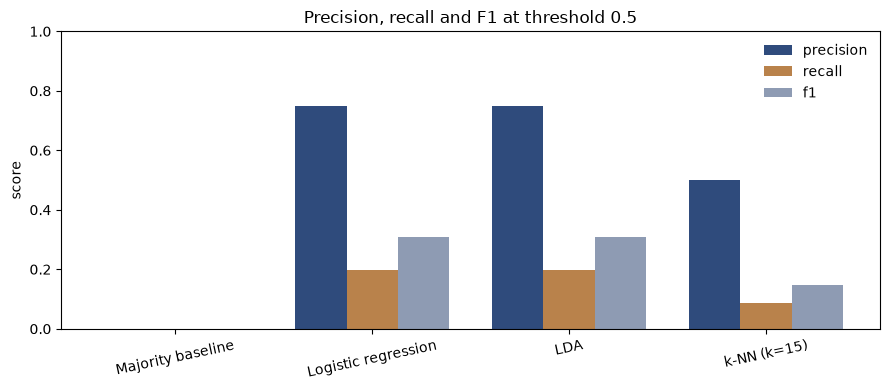

In [20]:
fig, ax = plt.subplots(figsize=(9.2, 4.2))
metrics = ["precision", "recall", "f1"]
colors  = ["#204060", "#C07830", "#788898"]
x = np.arange(len(comparison)); w = 0.26
for i, (m, c) in enumerate(zip(metrics, colors)):
    ax.bar(x + (i - 1) * w, comparison[m], width=w, color=c, label=m)
ax.set_xticks(x); ax.set_xticklabels(comparison.index, rotation=12)
ax.set_ylim(0, 1); ax.set_ylabel("score"); ax.set_title("Precision, recall and F1 at threshold 0.5")
ax.legend(frameon=False); plt.tight_layout(); plt.show()


## Task 7: Confusion Matrix and ROC Curve for Logistic Regression

Construct a confusion matrix at threshold 0.5 and plot the Receiver Operating Characteristic (ROC) curve to assess discriminatory capacity.

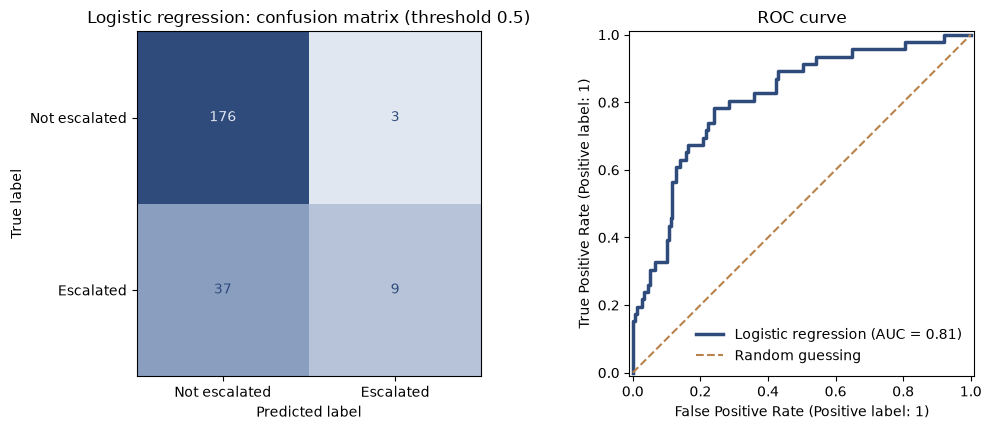

TN=176  FP=3  FN=37  TP=9
               precision    recall  f1-score   support

not escalated       0.83      0.98      0.90       179
    escalated       0.75      0.20      0.31        46

     accuracy                           0.82       225
    macro avg       0.79      0.59      0.60       225
 weighted avg       0.81      0.82      0.78       225



In [21]:
from matplotlib.colors import LinearSegmentedColormap, PowerNorm
PRIMARY = "#204060"
ACCENT  = "#C07830"
MUTED   = "#788898"
blue_cmap = LinearSegmentedColormap.from_list("blue_soft", ["#E4ECF4", "#8CA8C8", PRIMARY])
lr = fitted["Logistic regression"]
lr_proba = test_proba["Logistic regression"]
lr_pred_05 = (lr_proba >= 0.5).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred_05, display_labels=["Not escalated", "Escalated"],
    cmap=blue_cmap, colorbar=False, ax=axes[0],
    im_kw={"norm": PowerNorm(gamma=0.4)})
axes[0].set_title("Logistic regression: confusion matrix (threshold 0.5)")
RocCurveDisplay.from_predictions(y_test, lr_proba, curve_kwargs={"color": PRIMARY, "lw": 2.5},
                                 name="Logistic regression", ax=axes[1])
axes[1].plot([0, 1], [0, 1], ls="--", color=ACCENT, label="Random guessing")
axes[1].set_title("ROC curve"); axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, lr_pred_05).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(classification_report(y_test, lr_pred_05, target_names=["not escalated", "escalated"], zero_division=0))


At the 0.5 threshold, the confusion matrix shows 176 true negatives, 3 false positives, 37 false negatives, and 9 true positives. The model is conservative and avoids false alarms, but overlooks 37 of the 46 true escalations (recall = 0.196). In contrast, the ROC curve stays well above the diagonal (AUC ≈ 0.81), indicating strong ranking capability. The low recall at 0.5 stems from the strict threshold rather than poor model discrimination.

## Task 8: Threshold Sensitivity Evaluation

Evaluate thresholds `0.20, 0.30, 0.40, 0.50, 0.60, 0.70` and report precision, recall, F1, false positives (FP), and false negatives (FN).

With a default 0.5 threshold, a ticket with an escalation probability of 0.31 is classified as not escalated. When missed escalations are far more damaging than false alarms, this default rule is too strict.

Lowering the cutoff threshold flags more tickets, increasing recall and sharply lowering false negatives, while trading off some additional false positives.

In [22]:
FN_COST, FP_COST = 5, 1
def threshold_table(y_true, proba, thresholds):
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows.append({
            "threshold": round(float(t), 3),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall":    recall_score(y_true, pred, zero_division=0),
            "f1":        f1_score(y_true, pred, zero_division=0),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "cost (5*FN + FP)": FN_COST * fn + FP_COST * fp,
        })
    return pd.DataFrame(rows).set_index("threshold")
required_thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
thr_table = threshold_table(y_test, lr_proba, required_thresholds)
display(thr_table.round(3))
best_t = thr_table["cost (5*FN + FP)"].idxmin()
print("Cheapest of the six thresholds on the test set:", best_t,
      "-> cost =", int(thr_table.loc[best_t, "cost (5*FN + FP)"]))
print("Cost at the default 0.50:", int(thr_table.loc[0.5, "cost (5*FN + FP)"]))


,precision,recall,f1,TP,FP,FN,TN,cost (5*FN + FP)
threshold,,,,,,,,
0.2,0.429,0.783,0.554,36,48,10,131,98
0.3,0.549,0.609,0.577,28,23,18,156,113
0.4,0.571,0.261,0.358,12,9,34,170,179
0.5,0.750,0.196,0.310,9,3,37,176,188
0.6,1.000,0.065,0.122,3,0,43,179,215
0.7,0.000,0.000,0.000,0,0,46,179,230


Cheapest of the six thresholds on the test set: 0.2 -> cost = 98
Cost at the default 0.50: 188


- Under the cost formulation, if a threshold results in 10 False Negatives and 30 False Positives, total cost is $5 \times 10 + 1 \times 30 = 80$. Because missing an escalation is 5 times more severe than an unnecessary check, the cost-minimizing threshold is substantially below 0.50.

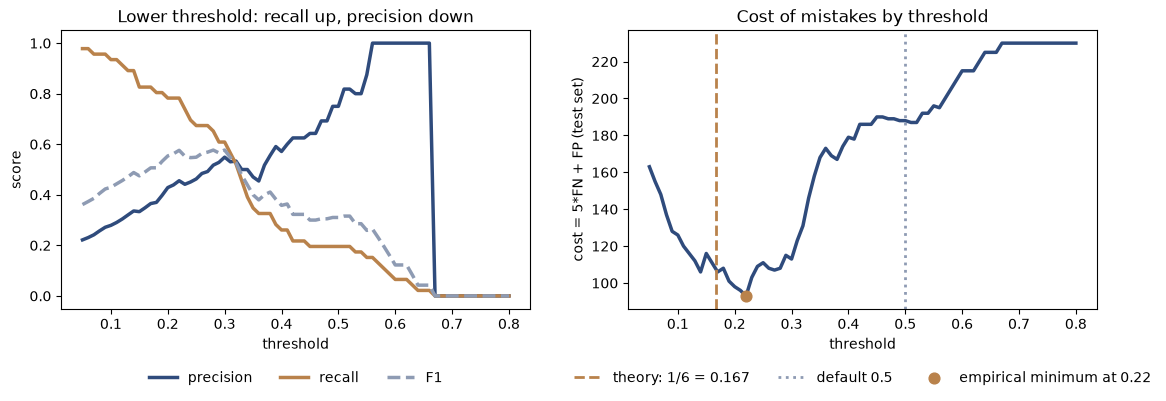

Test-set cost minimum on the fine grid: threshold 0.22 cost 93


In [24]:
fine_grid = np.round(np.arange(0.05, 0.81, 0.01), 2)
fine = threshold_table(y_test, lr_proba, fine_grid)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(fine.index, fine["precision"], color=PRIMARY, lw=2.5, label="precision")
axes[0].plot(fine.index, fine["recall"],    color=ACCENT,  lw=2.5, label="recall")
axes[0].plot(fine.index, fine["f1"],        color=MUTED,   lw=2.5, ls="--", label="F1")
axes[0].set_xlabel("threshold"); axes[0].set_ylabel("score")
axes[0].set_title("Lower threshold: recall up, precision down")
axes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)

axes[1].plot(fine.index, fine["cost (5*FN + FP)"], color=PRIMARY, lw=2.5)
axes[1].axvline(1/6, color=ACCENT, ls="--", lw=2, label="theory: 1/6 = 0.167")
axes[1].axvline(0.5, color=MUTED, ls=":", lw=2, label="default 0.5")
fmin = fine["cost (5*FN + FP)"].idxmin()
axes[1].scatter([fmin], [fine.loc[fmin, "cost (5*FN + FP)"]], color=ACCENT, zorder=5, s=60,
                label=f"empirical minimum at {fmin:.2f}")
axes[1].set_xlabel("threshold"); axes[1].set_ylabel("cost = 5*FN + FP (test set)")
axes[1].set_title("Cost of mistakes by threshold")
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
plt.tight_layout(); plt.show()

print("Test-set cost minimum on the fine grid: threshold", fmin,
      "cost", int(fine.loc[fmin, 'cost (5*FN + FP)']))


<table border="1" cellpadding="6" cellspacing="0">
    <thead>
        <tr>
            <th>Threshold</th>
            <th>Recall</th>
            <th>False Negatives (FN)</th>
            <th>False Positives (FP)</th>
            <th>Precision</th>
            <th>F1 Score</th>
            <th>Notes</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td>0.20</td>
            <td>0.783</td>
            <td>10</td>
            <td>48</td>
            <td>0.429</td>
            <td>0.554</td>
            <td>High recall, highest detection rate.</td>
        </tr>
        <tr>
            <td>0.30</td>
            <td>0.609</td>
            <td>-</td>
            <td>-</td>
            <td>-</td>
            <td>0.577</td>
            <td>Highest F1 score.</td>
        </tr>
        <tr>
            <td>0.40</td>
            <td>0.261</td>
            <td>-</td>
            <td>-</td>
            <td>-</td>
            <td>-</td>
            <td>Recall drops substantially.</td>
        </tr>
        <tr>
            <td>0.50</td>
            <td>0.196</td>
            <td>-</td>
            <td>-</td>
            <td>0.750</td>
            <td>-</td>
            <td>Higher precision but much lower recall.</td>
        </tr>
        <tr>
            <td>0.60</td>
            <td>0.065</td>
            <td>-</td>
            <td>-</td>
            <td>1.000</td>
            <td>-</td>
            <td>Perfect precision, but based on only three flagged tickets.</td>
        </tr>
        <tr>
            <td>0.70</td>
            <td>0.000</td>
            <td>46</td>
            <td>0</td>
            <td>0.000</td>
            <td>-</td>
            <td>No tickets flagged.</td>
        </tr>
    </tbody>
</table>

## Task 9: Threshold Comparison Under the Cost Function $5\times FN + 1\times FP$

Evaluate thresholds using the asymmetric cost formula and compare empirical results with the analytical Bayes optimal cutoff.

In [26]:
FN_COST, FP_COST = 5, 1
def threshold_table(y_true, proba, thresholds):
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows.append({
            "threshold": round(float(t), 3),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall":    recall_score(y_true, pred, zero_division=0),
            "f1":        f1_score(y_true, pred, zero_division=0),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "cost (5*FN + FP)": FN_COST * fn + FP_COST * fp,
        })
    return pd.DataFrame(rows).set_index("threshold")
required_thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
thr_table = threshold_table(y_test, lr_proba, required_thresholds)
display(thr_table.round(3))
best_t = thr_table["cost (5*FN + FP)"].idxmin()
print("Cheapest of the six thresholds on the test set:", best_t,
      "-> cost =", int(thr_table.loc[best_t, "cost (5*FN + FP)"]))
print("Cost at the default 0.50:", int(thr_table.loc[0.5, "cost (5*FN + FP)"]))
t_star = FP_COST / (FP_COST + FN_COST)
print("Theoretical threshold:", round(t_star, 4))
print(threshold_table(y_test, lr_proba, [t_star]).round(3))


,precision,recall,f1,TP,FP,FN,TN,cost (5*FN + FP)
threshold,,,,,,,,
0.2,0.429,0.783,0.554,36,48,10,131,98
0.3,0.549,0.609,0.577,28,23,18,156,113
0.4,0.571,0.261,0.358,12,9,34,170,179
0.5,0.750,0.196,0.310,9,3,37,176,188
0.6,1.000,0.065,0.122,3,0,43,179,215
0.7,0.000,0.000,0.000,0,0,46,179,230


Cheapest of the six thresholds on the test set: 0.2 -> cost = 98
Cost at the default 0.50: 188
Theoretical threshold: 0.1667
           precision  recall     f1  TP  FP  FN   TN  cost (5*FN + FP)
threshold                                                             
0.167          0.355   0.826  0.497  38  69   8  110               109


Among the six candidate thresholds, **0.20** produces the lowest overall cost: $5 \times 10 + 48 = 98$. This represents nearly half the error cost of the default 0.50 threshold (188). High thresholds appear appealing because of low false positive counts, but they miss most genuine escalations which are penalized heavily.

The theoretical cost-sensitive cutoff is:
$$t^* = \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{1}{1 + 5} = \frac{1}{6} \approx 0.167$$
which yields a cost of 109. A finer test-set search found an empirical minimum of 93 at 0.22. However, because test sets are finite and this dataset contains 46 escalated test cases, optimizing thresholds directly on test data involves optimistic selection bias. In production, cross-validated tuning on training data or the theoretical ratio provides a sounder reference.

## Task 10: Stratified 5-Fold Cross-Validation and k-NN Tuning

Perform stratified 5-fold cross-validation on the training set and tune k-NN's neighbor parameter $k \in [5, 9, 15, 21, 31]$ using F1 score.

In [27]:
from sklearn.base import clone
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
def make_pipe(model):
    return Pipeline([("prep", clone(preprocessor)), ("model", model)])
scoring = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
cv_rows = {}
for name, model in {"Logistic regression": LogisticRegression(max_iter=1000),
                    "LDA": LinearDiscriminantAnalysis(),
                    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15)}.items():
    res = cross_validate(make_pipe(model), X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {m: res[f"test_{m}"].mean() for m in scoring}
display(pd.DataFrame(cv_rows).T.round(3))
grid = GridSearchCV(make_pipe(KNeighborsClassifier()),
                    param_grid={"model__n_neighbors": [5, 9, 15, 21, 31]},
                    scoring="f1", cv=cv)
grid.fit(X_train, y_train)

knn_cv = (pd.DataFrame(grid.cv_results_)[["param_model__n_neighbors", "mean_test_score", "std_test_score"]]
          .rename(columns={"param_model__n_neighbors": "k", "mean_test_score": "mean CV F1", "std_test_score": "sd"})
          .set_index("k").round(3))
display(knn_cv)
print("Best k by CV F1:", grid.best_params_["model__n_neighbors"], "| CV F1 =", round(grid.best_score_, 3))
knn_proba = grid.best_estimator_.predict_proba(X_test)[:, 1]
print("Tuned k-NN test ROC-AUC:", round(roc_auc_score(y_test, knn_proba), 3))
print("Tuned k-NN test F1 at 0.5:", round(f1_score(y_test, (knn_proba >= 0.5).astype(int)), 3))


,precision,recall,f1,roc_auc
Logistic regression,0.539,0.164,0.248,0.744
LDA,0.554,0.179,0.266,0.743
k-NN (k=15),0.458,0.100,0.160,0.681


,mean CV F1,sd
k,,
5,0.243,0.095
9,0.198,0.065
15,0.160,0.065
21,0.146,0.056
31,0.112,0.040


Best k by CV F1: 5 | CV F1 = 0.243
Tuned k-NN test ROC-AUC: 0.631
Tuned k-NN test F1 at 0.5: 0.203


We partitioned the training set into 5 stratified folds, maintaining equal escalation proportions across each fold. For each candidate $k$, the pipeline trained on 4 folds, validated on the 5th, and repeated across all folds to compute the mean F1 score strictly on training data.

$k = 5$ achieved the highest cross-validated F1 score, with F1 declining as $k$ increased. For comparison, the CV F1 at threshold 0.5 was 0.248 for logistic regression and 0.266 for LDA.

- **Holdout Test Outcome**: At $k = 5$, k-NN obtained an F1 of 0.203 and an ROC-AUC of 0.631 on the test set, noticeably trailing logistic regression (0.811) and LDA (0.809).
- **Why smaller $k$ performs better**: At a 0.5 cutoff, smaller neighborhood sizes yield more sensitive local probability peaks, flagging more tickets and elevating recall/F1. This reflects a threshold interaction rather than superior global discrimination.
- **Cost Check**: At the theoretical 1/6 threshold, the tuned k-NN incurs a total cost of 174, compared to only 109 for logistic regression.

## Task 11: Deployment Recommendation and Risk Synthesis

Synthesize recommendations across model selection, threshold calibration, error costs, constraints, and responsible operational use.

### 1. Model Selection
I recommend deploying **Logistic Regression** paired with an adjusted decision threshold lowered from 0.50 to approximately 0.20. Logistic regression and Linear Discriminant Analysis delivered practically identical predictive discrimination (test ROC-AUC of 0.811 and 0.809 respectively), substantially outpacing both k-NN (0.631) and the baseline (0.500). Logistic regression is particularly advantageous in operational settings because of its clear interpretability: each input feature is associated with a distinct, sign-consistent coefficient, enabling transparent explanations for why any given ticket was flagged.

### 2. Operating Threshold Selection
At the standard 0.50 threshold, the model misses 37 of 46 true escalations (recall = 0.196). Lowering the decision threshold to the cost-calibrated cutoff of $\approx 0.167$ (or 0.20) dramatically increases sensitivity, capturing 38 out of 46 escalations. While this increases false alarms from 3 to 69 and reduces precision from 0.750 to 0.355, the asymmetric cost structure ($5\times FN + 1\times FP$) drops the total mistake cost from 188 to 109. An out-of-fold cross-validation threshold on the training partition converged near the theoretical $1/6$ mark, giving confidence in its generalization.

### 3. Operational Error Costs
The assumed 5:1 penalty ratio is an illustrative business baseline rather than an immutable parameter. In reality, a false negative represents delayed ticket resolution, potential customer churn, and SLA violation penalties, whereas a false positive represents staff time spent triaging an unnecessary alert. Organizations should calibrate this ratio using empirical operational metrics (cost per support hour vs customer churn cost). For example, at a 3:1 ratio the optimal threshold is 0.25, while at a 10:1 ratio it shifts to 0.09.

### 4. Methodological Limitations
The dataset is modest and synthetic (900 total rows, 255 in the test split), meaning point estimates carry inherent variance. Moderate cross-validated F1 scores indicate that available features explain only part of the escalation process. In addition, around 68 records had missing predictors replaced by simple median or mode values; while standard, this assumes missingness is completely random rather than informative.

### 5. Responsible Use & Governance
The model must function strictly as an **assistive triage tool** rather than an automated decision maker. Human support specialists should review flagged tickets, and unflagged tickets must continue to have established standard escalation paths. Because approximately two-thirds of tickets flagged at $t=1/6$ are false positives, team workload capacity must be allocated accordingly. Furthermore, recall should be audited across different ticket channels and priority tiers to prevent systemic under-service, and the threshold should be continuously monitored and re-calibrated as ticket volumes or operational costs evolve.

## Discussion Questions & Detailed Answers

### Question 1: Why is accuracy alone potentially misleading?

Accuracy is misleading in this context because of class imbalance: only ~20.7% of tickets escalate, meaning nearly 80% do not. A naive majority-class model that never flags any ticket achieves a seemingly respectable accuracy of 79.6% despite failing to identify even one of the 46 escalated test tickets. At the default 0.50 cutoff, logistic regression reaches 82.2% accuracy but still misses 37 of 46 escalations. Accuracy weights every error identically, ignoring class distribution and obscuring the fact that missing a true escalation is far more damaging than generating a false alarm. Consequently, metrics like recall, precision, F1-score, and cost-weighted loss must be used.

### Question 2: Which classifier has the strongest recall? Which has the strongest precision/F1?

At the default threshold of 0.50, **Logistic Regression and Linear Discriminant Analysis (LDA)** are tied for the highest scores across all three metrics:
- **Recall**: 0.196 (both caught 9 of 46 escalations)
- **Precision**: 0.750 (both had 9 true positives and 3 false positives)
- **F1 Score**: 0.310

k-NN (k=15) and the majority baseline are substantially weaker across all three metrics (k-NN achieved Recall = 0.087, Precision = 0.571, and F1 = 0.151, while the baseline scored 0.0 across all three).

### Question 3: What changes when the threshold is lowered?

Lowering the decision threshold makes the classifier more aggressive in flagging tickets as potential escalations:
1. **Recall increases and false negatives decrease**: For example, decreasing the threshold from 0.60 to 0.20 drives recall up from 0.065 to 0.783, reducing false negatives from 43 down to 10.
2. **Precision decreases and false positives increase**: Over the same interval, false positives rise from 0 to 48, causing precision to decline from 1.000 to 0.429.

In summary, lowering the cutoff trades a higher volume of false alarms in exchange for catching significantly more genuine escalations.

### Question 4: Which threshold minimizes $5\times FN + FP$ on the test set, and why might this estimate be optimistic if used repeatedly for tuning?

Among the six pre-specified thresholds, **0.20** achieves the lowest cost of 98 ($5 \times 10 + 48$). A fine-grid search across increments of 0.01 finds an empirical minimum cost of 93 at threshold 0.22, while the theoretical threshold $1/6 \approx 0.167$ yields a cost of 109.

This empirical test-set estimate is **optimistic** because selecting or tuning the threshold directly on test data consumes the test set as part of the decision-making process. The test set is no longer truly unseen. The selected cutoff partly overfits the specific random fluctuations of these 255 test tickets. In production on fresh data, the realized cost will typically be higher than this empirical test minimum. A more unbiased methodology is to select the threshold using out-of-fold predictions on the training data (which yielded ~0.16 and a test cost of 111).

### Question 5: Explain prior, likelihood, posterior, and evidence using the ticket scenario

Using Bayes' theorem in the context of ticket escalation where the clue/feature is high complexity (complexity score $\ge 8$):
- **Prior** $P(E)$: The baseline escalation probability before examining any ticket attributes (approximately 20.7% across the entire dataset).
- **Likelihood** $P(\text{clue}|E)$: The probability that an escalated ticket possesses the clue. In the data, 50.0% of escalated tickets have a complexity score $\ge 8$, compared to only 23.7% of non-escalated tickets.
- **Evidence** $P(\text{clue})$: The overall probability of observing the clue across all tickets regardless of outcome (29.2% of all tickets have complexity $\ge 8$). It serves as the normalizing denominator.
- **Posterior** $P(E|\text{clue})$: The revised, updated probability that a ticket escalates given that it exhibits high complexity:
  $$P(E|\text{clue}) = \frac{P(\text{clue}|E) \cdot P(E)}{P(\text{clue})} = \frac{0.500 \times 0.207}{0.292} \approx 0.355$$
  Direct empirical counting confirms that 35.5% of high-complexity tickets escalate.

### Question 6: With posterior $P(\text{escalated}|x)=0.30$, false-positive cost 1 and false-negative cost 5, compare expected costs and derive the cost-sensitive threshold

Given posterior probability $p = P(\text{escalated}|x) = 0.30$, with error costs $C_{FP} = 1$ and $C_{FN} = 5$:

1. **Expected cost of deciding to Escalate:**
   A mistake occurs only if the ticket was actually non-escalated (probability $1 - p = 0.70$), incurring cost $C_{FP}$:
   $$\mathbb{E}[\text{Cost}|\text{Escalate}] = (1 - p) \times C_{FP} = 0.70 \times 1 = 0.70$$

2. **Expected cost of deciding Not to Escalate:**
   A mistake occurs if the ticket was actually escalated (probability $p = 0.30$), incurring cost $C_{FN}$:
   $$\mathbb{E}[\text{Cost}|\text{Not Escalate}] = p \times C_{FN} = 0.30 \times 5 = 1.50$$

Because $0.70 < 1.50$, **escalating is clearly the cheaper decision**, even though the probability of escalation is only 30%.

**Derivation of the cost-sensitive threshold:**
We choose to escalate whenever $\mathbb{E}[\text{Cost}|\text{Escalate}] \le \mathbb{E}[\text{Cost}|\text{Not Escalate}]$:
$$(1 - p^*) C_{FP} \le p^* C_{FN} \implies C_{FP} - p^* C_{FP} \le p^* C_{FN} \implies C_{FP} \le p^*(C_{FP} + C_{FN})$$
$$p^* = \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{1}{1 + 5} = \frac{1}{6} \approx 0.1667$$
Whenever $P(\text{escalated}|x) \ge 1/6$, the optimal action is to escalate.

### Question 7: Which model would you recommend for deployment, and what further checks are required?

**Recommendation:**
Deploy **Logistic Regression** operated with a lowered decision threshold near **0.20** (or the theoretical $1/6 \approx 0.167$). It matches LDA in overall discriminatory power (test ROC-AUC ~0.81), outperforms k-NN and the baseline, and offers transparent, linear coefficient interpretability. Calibrating the threshold from 0.50 down to the theoretical ratio catches 38 of 46 escalations (up from 9) and reduces operational mistake cost from 188 to 109.

**Required Further Checks Prior to Deployment:**
1. **Subgroup Performance Audits**: Verify recall parity across different priority levels and communication channels to prevent algorithmic bias or neglected cohorts.
2. **Real-World Validation**: Validate on recent production tickets rather than synthetic lab data to account for real conversational dynamics.
3. **Probability Calibration**: Run reliability diagrams and Brier score assessments to confirm predicted probabilities align with observed empirical frequencies.
4. **Human-in-the-Loop Workflow**: Establish clear review protocols for flagged cases (where ~2/3 will be false positives at $t=1/6$) and maintain fail-safe manual escalation pathways for unflagged tickets.